In [6]:
%pip install antspyx
%pip install tqdm
%pip install ipywidgets
%pip install torch
%pip install scikit-image
%pip install --upgrade SimpleITK
%pip install nibabel
%pip install nipype nilearn matplotlib


[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/o

In [1]:
import os
import ants
import numpy as np
from pathlib import Path
from tqdm import tqdm
from ipywidgets import interact, IntSlider, Dropdown
import matplotlib.pyplot as plt
import torch
from skimage import draw, measure, color, filters, segmentation, morphology
from scipy import ndimage
import numpy as np
from scipy.ndimage import center_of_mass
from skimage.measure import regionprops
from preprocess import Preprocess
import warnings
from scipy.ndimage import binary_fill_holes
from scipy.spatial import ConvexHull
import numpy as np
from scipy.ndimage import label, distance_transform_edt, binary_dilation
from skimage.measure import regionprops
from skimage import morphology
warnings.filterwarnings('ignore')
from scipy.ndimage import label, center_of_mass 
from skimage import morphology
from skimage.measure import regionprops
import numpy as np

In [2]:
def load_slice(image_path, slice_idx=None, axis=2):
    """
    Load MRI and extract a 2D slice
    
    Args:
        image_path: path to NIfTI
        slice_idx: which slice (None = middle)
        axis: 0=sagittal, 1=coronal, 2=axial
    
    Returns:
        img: ANTs image
        slice_2d: 2D numpy array
        slice_idx: actual slice index used
    """
    img = ants.image_read(str(image_path))
    data_3d = img.numpy()
    
    # Get middle slice if not specified
    if slice_idx is None:
        slice_idx = data_3d.shape[axis] // 2
    
    # Extract slice
    if axis == 0:
        slice_2d = data_3d[slice_idx, :, :]
    elif axis == 1:
        slice_2d = data_3d[:, slice_idx, :]
    else:  # axis == 2
        slice_2d = data_3d[:, :, slice_idx]
    
    print(f"Loaded slice {slice_idx} (axis={axis})")
    print(f"  Shape: {slice_2d.shape}")
    print(f"  Range: [{slice_2d.min():.2f}, {slice_2d.max():.2f}]")
    
    return img, slice_2d, slice_idx

def fill_brain(img_slice, clean_brain_mask, head_mask=None):
    tight_hull = morphology.convex_hull_image(clean_brain_mask)
    closed_brain = tight_hull & head_mask if head_mask is not None else tight_hull
    closed_brain = morphology.binary_closing(closed_brain, morphology.disk(5))
    thin_boundary = closed_brain ^ morphology.binary_erosion(closed_brain, morphology.disk(1))

    brain_only = np.where(closed_brain, img_slice, 0)
    
    return brain_only

def convert_to_mask(img_slice, contour):
    mask = np.zeros(img_slice.shape, dtype=np.uint8)

    r = contour[:, 0]
    c = contour[:, 1]

    # 3. Generate the pixel indices that fall inside the polygon
    rr, cc = draw.polygon(r, c, shape=mask.shape)

    # 4. Fill the mask with 1s (foreground)
    mask[rr, cc] = 1

    return mask


In [3]:
subject_number = '010'
subject_path = f'data/Train/subj{subject_number}'
img, img_slice, _ = load_slice(subject_path + f'/subj{subject_number}_image.nii.gz', 104, axis=2)
cat_mask, mask_slice, _ = load_slice(subject_path + f'/subj{subject_number}_catheter.nii.gz', 104, axis=2)

Loaded slice 104 (axis=2)
  Shape: (192, 224)
  Range: [0.00, 312.88]
Loaded slice 104 (axis=2)
  Shape: (192, 224)
  Range: [0.00, 2.00]


In [4]:
def view_slice_multi(image_data, mask_data, axis_name, slice_idx):
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    axis = axis_map[axis_name]

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    def get_slice(volume, idx, ax):
        if volume is None: return None
        # Use simple indexing based on axis
        if ax == 0: return volume[idx, :, :].T
        if ax == 1: return volume[:, idx, :].T
        if ax == 2: return volume[:, :, idx].T
        return None

    # Get the slices from the passed-in data
    img_slice = get_slice(image_data, slice_idx, axis)
    
    titles = [f'MRI ({axis_name})', 'MRI + Artifact']
    vmin, vmax = image_data.min(), image_data.max()
    
    for i in range(2):
        axes[i].imshow(img_slice, cmap='gray', vmin=vmin, vmax=vmax, origin='lower')
        axes[i].axis('off')
            
    if mask_data is not None:
        a_slice = get_slice(mask_data, slice_idx, axis)
        if a_slice is not None and a_slice.max() > 0:
            axes[1].contour(a_slice, levels=[0.5], colors='red', linewidths=2)
            axes[1].contourf(a_slice, levels=[0.5, 1], colors='red', alpha=0.3)

    for i, title in enumerate(titles):
        axes[i].set_title(f"{title} - Slice {slice_idx}")
        
    plt.tight_layout()
    plt.show()

def start_interactive_viewer(image_tensor, mask_tensor, initial_axis='Axial (S-I)'):
    img_np = image_tensor.numpy()if hasattr(image_tensor, 'numpy') else image_tensor
    mask_np = mask_tensor.numpy() if hasattr(mask_tensor, 'numpy') else mask_tensor
    
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    
    def internal_update(axis_name):
        # Calculate max slices for this specific image and axis
        max_idx = img_np.shape[axis_map[axis_name]] - 1
        
        interact(lambda idx, name: view_slice_multi(img_np, mask_np, name, idx), 
                 name=Dropdown(options=['Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-R)'], value=axis_name),
                 idx=IntSlider(min=0, max=max_idx, step=1, value=max_idx//2, continuous_update=False))

    internal_update(initial_axis)

start_interactive_viewer(img, cat_mask)

interactive(children=(IntSlider(value=95, continuous_update=False, description='idx', max=191), Dropdown(descr…

In [15]:
preprocess = Preprocess('templates/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii')
reg_image, reg_mask, template = preprocess.preprocess_subject(subject_path + f'/subj{subject_number}_image.nii.gz', 
                                                              subject_path + f'/subj{subject_number}_catheter.nii.gz',
                                                              Path(subject_path))

In [ ]:
start_interactive_viewer(reg_image, reg_mask)

interactive(children=(IntSlider(value=96, continuous_update=False, description='idx', max=192), Dropdown(descr…

In [4]:
%pip install nipype
%pip install nilearn


[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
  Using cached nilearn-0.13.1-py3-none-any.whl.metadata (12 kB)
Using cached nilearn-0.13.1-py3-none-any.whl (10.6 MB)

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
from nipype.interfaces import fsl
import matplotlib.pyplot as plt
from nilearn import plotting

# 1. Tell Nipype where FSL is (usually /usr/local/fsl)
# This step is critical if FSL isn't in your PATH
os.environ['FSLDIR'] = '/Users/maazshamim/fsl'
os.environ['PATH'] += os.pathsep + '/Users/maazshamim/fsl/bin'

def run_bet(input_path, output_path):
    # Initialize the BET interface
    bet = fsl.BET()
    bet.inputs.in_file = input_path
    bet.inputs.out_file = output_path
    bet.inputs.mask = True          # Generates a binary mask too
    bet.inputs.frac = 0.5           # Robustness parameter (0 to 1)
    
    print(f"Running BET on {input_path}...")
    res = bet.run()
    print("Done!")
    return res.outputs.out_file, res.outputs.mask_file

# Run it
brain_ext, brain_mask = run_bet(subject_path + f'/subj{subject_number}_image.nii.gz', subject_path + 'skull_stripped_output.nii.gz')

NameError: name 'subject_path' is not defined

In [67]:
img = ants.image_read(subject_path + f'/subj{subject_number}_image.nii.gz')
mask = ants.image_read(brain_mask)

# 3. Convert to numpy for the multiplication
img_np = img.numpy()
mask_np = mask.numpy()

# 4. Apply the mask
# FSL masks are 1 for brain, 0 for skull. Multiplication clears the skull.
brain_np = img_np * mask_np

ValueError: File ./data/Train/subj/subj001_image.nii.gz does not exist!

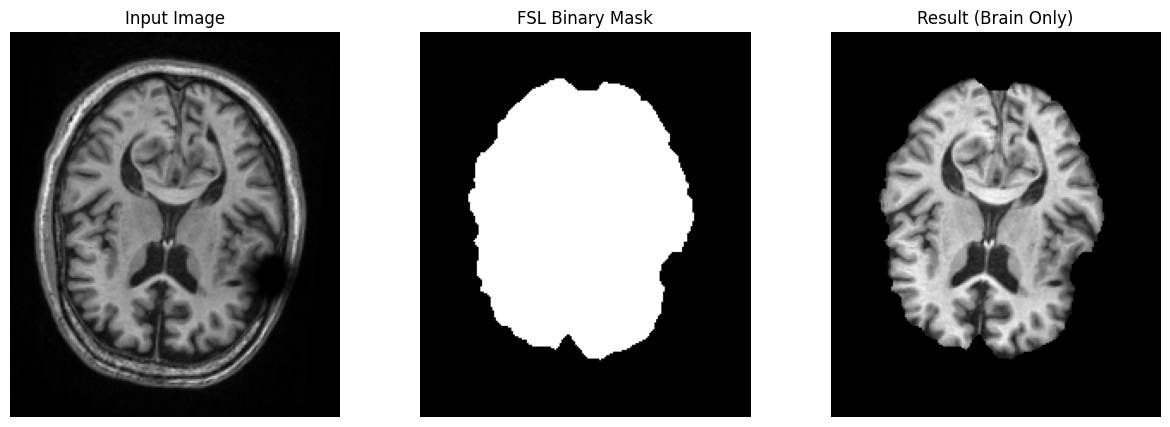

In [48]:
slice_idx = img_np.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original (Input to FSL)
axes[0].imshow(np.rot90(img_np[:, :, slice_idx]), cmap='gray')
axes[0].set_title("Input Image")

# Mask (The 'brain_mask' file from FSL)
axes[1].imshow(np.rot90(mask_np[:, :, slice_idx]), cmap='bone')
axes[1].set_title("FSL Binary Mask")

# Result (The 'brain_ext' part)
axes[2].imshow(np.rot90(brain_np[:, :, slice_idx]), cmap='gray')
axes[2].set_title("Result (Brain Only)")

for ax in axes: ax.axis('off')
plt.show()

In [1]:
import os
import ants
from pathlib import Path
from preprocess import Preprocess

# CONFIG
subject_path    = './data/Train/subj'
subject_number  = '001'
template_path   = 'templates/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii'
output_dir      = Path('./outputs')
output_dir.mkdir(parents=True, exist_ok=True)

subject_image    = f'{subject_path}{subject_number}/subj{subject_number}_image.nii.gz'
subject_catheter = f'{subject_path}{subject_number}/subj{subject_number}_catheter.nii.gz'

# EXECUTION
print("Registering to Atlas...")
preprocess = Preprocess(template_path)
reg_img, reg_mask, template = preprocess.preprocess_subject(subject_image, subject_catheter, output_dir)

# Save as standard NIfTI files
ants.image_write(reg_img, str(output_dir / f'subj{subject_number}_reg_image.nii.gz'))
ants.image_write(reg_mask, str(output_dir / f'subj{subject_number}_reg_mask.nii.gz'))
ants.image_write(template, str(output_dir / f'subj{subject_number}_template.nii.gz'))

print("Registration Saved. You can now close this and use the analysis script.")

Registering to Atlas...
Registration Saved. You can now close this and use the analysis script.


In [ ]:
slice_idx = img_np.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original (Input to FSL)
axes[0].imshow(np.rot90(img_np[:, :, slice_idx]), cmap='gray')
axes[0].set_title("Input Image")

# Mask (The 'brain_mask' file from FSL)
axes[1].imshow(np.rot90(mask_np[:, :, slice_idx]), cmap='bone')
axes[1].set_title("FSL Binary Mask")

# Result (The 'brain_ext' part)
axes[2].imshow(np.rot90(brain_np[:, :, slice_idx]), cmap='gray')
axes[2].set_title("Result (Brain Only)")

for ax in axes: ax.axis('off')
plt.show()

In [6]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
from nipype.interfaces import fsl

# CONFIG
subject_number = '001'
output_dir     = Path('./outputs')
os.environ['FSLDIR'] = '/Users/maazshamim/fsl'
os.environ['PATH'] += os.pathsep + f"{os.environ['FSLDIR']}/bin"

# 1. Load the pre-registered files
reg_path      = output_dir / f'subj{subject_number}_reg_image.nii.gz'
mask_path     = output_dir / f'subj{subject_number}_reg_mask.nii.gz'
template_path = 'templates/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii'

# 2. Run FSL BET on SUBJECT
bet_subj = fsl.BET(in_file=str(reg_path), out_file=str(output_dir/f'subj{subject_number}_brain.nii.gz'),
                   mask=True, frac=0.5, robust=True, output_type='NIFTI_GZ')
bet_subj.run()
brain_data = nib.load(output_dir/f'subj{subject_number}_brain.nii.gz').get_fdata()

# 3. Run FSL BET on TEMPLATE
# We save this so we don't have to keep re-running it for every subject
temp_brain_path = output_dir / f'template_brain.nii.gz'
if not temp_brain_path.exists():
    bet_temp = fsl.BET(in_file=str(template_path), out_file=str(temp_brain_path),
                       mask=True, frac=0.5, robust=True, output_type='NIFTI_GZ')
    bet_temp.run()
template_brain_data = nib.load(temp_brain_path).get_fdata()

# 4. Subtraction Logic with Absolute Difference
def normalize(arr):
    # Only normalize based on voxels inside the brain (non-zero)
    v = arr[arr > 0]
    if len(v) == 0: return arr
    # Using 1st and 99th percentile to be extra robust against the catheter's brightness
    p1, p99 = np.percentile(v, [1, 99])
    return np.clip((arr - p1) / (p99 - p1 + 1e-8), 0, 1)

def get_voids_estimation(subject_data, template_data, t_bright_thresh=0.4, s_dark_thresh=0.15):
    # 1. Normalize both to 0-1
    s_norm = normalize(subject_data)
    t_norm = normalize(template_data)
    
    # 2. Logic: Where is the Template bright BUT the Subject is dark?
    # This ignores areas where both are dark (like outside the brain)
    # and areas where both are bright (normal white/gray matter).
    template_is_bright = t_norm > t_bright_thresh
    subject_is_dark    = s_norm < s_dark_thresh
    
    # 3. Combine: Intersection of these two conditions
    voids_mask = np.logical_and(template_is_bright, subject_is_dark)
    
    return voids_mask.astype(np.uint8)

estimation = get_voids_estimation(brain_data, template_brain_data)

# 5. Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
mid_z = brain_data.shape[2] // 2

# View 1: The Subject Brain
axes[0].imshow(np.rot90(brain_data[:,:,mid_z]), cmap='gray')
axes[0].set_title("BET Subject Brain")

# View 2: The Raw Difference (Should see Blue/Red dots on White/Grey background)
axes[1].imshow(np.rot90(diff[:,:,mid_z]), cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[1].set_title("Raw Difference (Subject-Temp)")

# View 3: The Estimation (The White Dot on Black background)
# We use a threshold to clean it up for the U-Net
clean_estimation = np.clip(estimation, 0, None)
axes[2].imshow(np.rot90(clean_estimation[:,:,mid_z]), cmap='magma', vmin=0, vmax=0.4)
axes[2].set_title("Estimation (Abs Difference)")

for ax in axes: ax.axis('off')
plt.show()

# 6. Save the final estimation for the U-Net
affine = nib.load(reg_path).affine
nib.save(nib.Nifti1Image(clean_estimation.astype(np.float32), affine), 
         output_dir / f'subj{subject_number}_estimation.nii.gz')

260511-00:05:54,834 nipype.interface WARNING:
	 FSLOUTPUTTYPE environment variable is not set. Setting FSLOUTPUTTYPE=NIFTI


OSError: No command "bet" found on host Maazs-MacBook-Air.local. Please check that the corresponding package is installed.

In [46]:
from ipywidgets import interact, IntSlider

def browse_slices(slice_idx):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#1e1e1e')
    
    # 1. Subject Brain
    axes[0].imshow(np.rot90(brain_data[:,:,slice_idx]), cmap='gray')
    axes[0].set_title(f"Subject Slice {slice_idx}", color='white')
    
    # 2. Raw Difference
    axes[1].imshow(np.rot90(estimation[:,:,slice_idx]), cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    axes[1].set_title("Raw Difference", color='white')
    
    # 3. Final Estimation (Overlay on Brain)
    # We overlay the estimation in Cyan on top of the gray brain
    bg = np.rot90(norm_brain[:,:,slice_idx])
    est = np.rot90(clean_estimation[:,:,slice_idx])
    
    overlay = np.stack([bg]*3, axis=-1)
    # Highlight anomalies in Cyan (R=0, G=1, B=1)
    mask = est > 0.1 
    overlay[mask] = [0, 1, 1] 
    
    axes[2].imshow(overlay)
    axes[2].set_title("Anomalies (Cyan Overlay)", color='white')
    
    for ax in axes: ax.axis('off')
    plt.show()

interact(browse_slices, slice_idx=IntSlider(min=0, max=brain_data.shape[2]-1, step=1, value=mid_z))

interactive(children=(IntSlider(value=96, description='slice_idx', max=192), Output()), _dom_classes=('widget-…

<function __main__.browse_slices(slice_idx)>